# 3. Editing & Extending Models

Now it's your turn to take control of the CSV files, rebuild the Julia ODEs with `CSV2Model`, and watch how biological perturbations reshape the dynamics!

:::{tip} Editing CSVs directly in the browser
When doing research in the lab, you can edit `reactions.csv`, `parameters.csv`, and `ratelaws.csv` in Excel or VS Code. Here in this interactive tutorial, we write the CSV tables straight from Julia code cells using `write(...)` so you can test ideas in seconds — and every change runs inside your own isolated workspace!
:::

First, let's load our Julia packages.

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames

gr()
println("Ready to build and modify models!")

Ready to build and modify models!


---

## Challenge 1: Make the rate that A is expressed 10× slower

Try and make the rate that **A** is expressed **10× slower** than in the original Toy Model. How does the graph change?

The cell below contains the **original unmodified Toy Model**. Edit it and press **Shift + Enter** to see the effect!

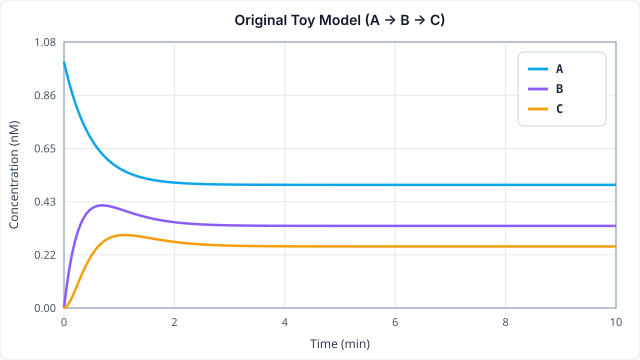

In [2]:
# Original unmodified Toy Model — edit this cell to solve Challenge 1!
write("parameters_ch1.csv", """
Parameter , Value
k1_Aexp   , 1
k1_AtoB   , 2
k1_BtoC   , 3
k1_Cdeg   , 4
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("parameters_ch1.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions.csv parameters_ch1.csv ratelaws.csv toyModel_ch1.jl`)
include("toyModel_ch1.jl")
include("variableNames.jl")

y0 = [1.0, 0.0, 0.0]
prob_ch1 = ODEProblem(ODEFunction(toyModel_ch1), y0, (0.0, 10.0))
sol_ch1 = solve(prob_ch1, abstol=1e-5, reltol=1e-3)

plot(
    sol_ch1,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 1: Toy Model",
    lw = 2.5,
)

```{admonition} 💡 Hint
:class: dropdown tip

You only need to change the `parameters_ch1.csv` file — specifically the value of `k1_Aexp`!
```

````{admonition} ✅ Reveal Solution
:class: dropdown note

1. In `parameters_ch1.csv`, change `k1_Aexp` from `1` to `0.1` (10× lower).
2. Re-run the cell so `CSV2Model` regenerates `toyModel_ch1.jl`, re-includes it, solves the ODEs, and plots the updated curves.
3. Notice that **A** settles much lower (`0.05 nM` instead of `0.5 nM`) — and so do **B** and **C**, because they are made from **A**!

```julia
write("parameters_ch1.csv", """
Parameter , Value
k1_Aexp   , 0.1
k1_AtoB   , 2
k1_BtoC   , 3
k1_Cdeg   , 4
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("parameters_ch1.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions.csv parameters_ch1.csv ratelaws.csv toyModel_ch1.jl`)
include("toyModel_ch1.jl")
include("variableNames.jl")

y0 = [1.0, 0.0, 0.0]
prob_ch1 = ODEProblem(ODEFunction(toyModel_ch1), y0, (0.0, 10.0))
sol_ch1 = solve(prob_ch1, abstol=1e-5, reltol=1e-3)

plot(
    sol_ch1,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 1 Solution: 10× Slower Expression of A",
    lw = 2.5,
)
```
````

---

## Challenge 2: Make A expressed 10× faster AND C degraded 10× faster

Try and make the rate that **A** is expressed **10× faster** (than its original value of `1`), **and** the rate that **C** is degraded **10× faster** too (than its original value of `4`). How does this change the graph?

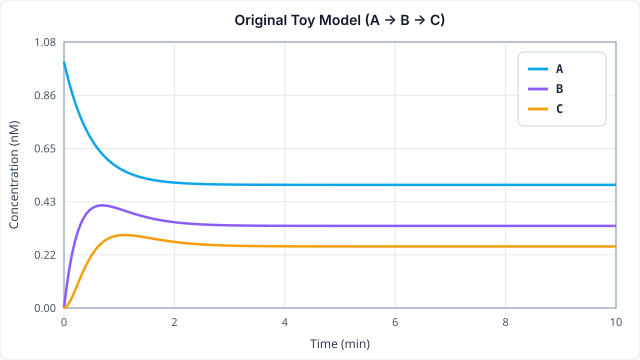

In [3]:
# Original unmodified Toy Model — edit this cell to solve Challenge 2!
write("parameters_ch2.csv", """
Parameter , Value
k1_Aexp   , 1
k1_AtoB   , 2
k1_BtoC   , 3
k1_Cdeg   , 4
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("parameters_ch2.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions.csv parameters_ch2.csv ratelaws.csv toyModel_ch2.jl`)
include("toyModel_ch2.jl")
include("variableNames.jl")

y0 = [1.0, 0.0, 0.0]
prob_ch2 = ODEProblem(ODEFunction(toyModel_ch2), y0, (0.0, 10.0))
sol_ch2 = solve(prob_ch2, abstol=1e-5, reltol=1e-3)

plot(
    sol_ch2,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 2: Toy Model",
    lw = 2.5,
)

```{admonition} 💡 Hint
:class: dropdown tip

You only need to edit two numbers in `parameters_ch2.csv`: `k1_Aexp` (originally `1`) and `k1_Cdeg` (originally `4`).
```

````{admonition} ✅ Reveal Solution
:class: dropdown note

1. In `parameters_ch2.csv`, multiply `k1_Aexp` by 10 (`1` → `10`) and multiply `k1_Cdeg` by 10 (`4` → `40`).
2. Re-run the cell. Notice how **A** and **B** jump up 10× (`5.0 nM` and `3.33 nM`), while **C** ends up right back at its original steady state (`0.25 nM`) because the 10× faster inflow from **B** cancels the 10× faster degradation of **C**!

```julia
write("parameters_ch2.csv", """
Parameter , Value
k1_Aexp   , 10
k1_AtoB   , 2
k1_BtoC   , 3
k1_Cdeg   , 40
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("parameters_ch2.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions.csv parameters_ch2.csv ratelaws.csv toyModel_ch2.jl`)
include("toyModel_ch2.jl")
include("variableNames.jl")

y0 = [1.0, 0.0, 0.0]
prob_ch2 = ODEProblem(ODEFunction(toyModel_ch2), y0, (0.0, 10.0))
sol_ch2 = solve(prob_ch2, abstol=1e-5, reltol=1e-3)

plot(
    sol_ch2,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 2 Solution: 10× Faster A Expression & C Degradation",
    lw = 2.5,
)
```
````

---

## Challenge 3: Add a whole new molecular species D!

Try and add a brand-new molecular species **D** so that the model becomes:

```{figure} ../images/toy-model-abcd.svg
:alt: Extended 4-species Toy Model diagram A to B to C to D
:width: 100%

Goal pathway: $\emptyset \to A \to B \to C \to D \to \emptyset$.
```

The cell below starts with the **original 3-species Toy Model**. Modify it to add **D** and simulate all four species!

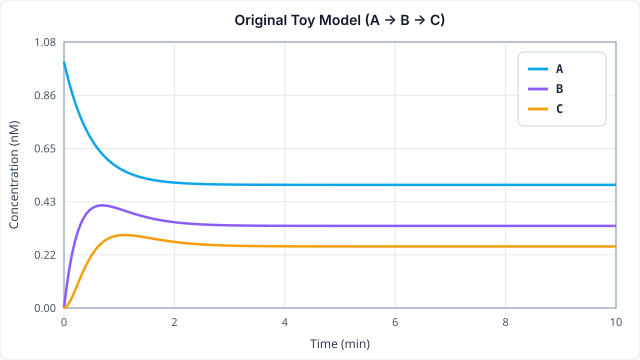

In [4]:
# Original 3-species Toy Model — edit this cell to add species D!
write("reactions_ch3.csv", """
Substrate , Products , Kinetic Law                , Modifiers , Parameters
          , A        , Constant Exp               ,           , k1_Aexp
A         , B        , Mass Action with substrate ,           , k1_AtoB
B         , C        , Mass Action with substrate ,           , k1_BtoC
C         ,          , Mass Action with substrate ,           , k1_Cdeg
""")

write("parameters_ch3.csv", """
Parameter , Value
k1_Aexp   , 1
k1_AtoB   , 2
k1_BtoC   , 3
k1_Cdeg   , 4
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("reactions_ch3.csv", DataFrame; stripwhitespace=true))
display(CSV.read("parameters_ch3.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions_ch3.csv parameters_ch3.csv ratelaws.csv toyModel_ch3.jl`)
include("toyModel_ch3.jl")
include("variableNames.jl")

y0_ch3 = [1.0, 0.0, 0.0]
prob_ch3 = ODEProblem(ODEFunction(toyModel_ch3), y0_ch3, (0.0, 10.0))
sol_ch3 = solve(prob_ch3, abstol=1e-5, reltol=1e-3)

plot(
    sol_ch3,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 3: Extend the Pathway",
    lw = 2.5,
)

```{admonition} 💡 Hint
:class: dropdown tip

You need to change **3 things**:
1. **`reactions_ch3.csv`**: Add a new reaction row for `C → D` (`k1_CtoD`), and update the degradation row so that **D** (not **C**) is degraded (`k1_Ddeg`).
2. **`parameters_ch3.csv`**: Give numerical values to your new parameters (for example `k1_CtoD,2` and `k1_Ddeg,4`).
3. **Initial conditions `y0_ch3`**: Your model now has **4** species (`A, B, C, D`), so `y0_ch3` needs 4 starting numbers!
```

````{admonition} ✅ Reveal Solution
:class: dropdown note

1. In `reactions_ch3.csv`, change the `C` degradation row to convert `C` into `D` (`C,D,Mass Action with substrate,,k1_CtoD`), and add a new 5th reaction for `D` degrading (`D,,Mass Action with substrate,,k1_Ddeg`).
2. In `parameters_ch3.csv`, add `k1_CtoD,2` and replace `k1_Cdeg,4` with `k1_Ddeg,4`.
3. Update `y0_ch3 = [1.0, 0.0, 0.0, 0.0]` so Julia has an initial concentration for all 4 species.
4. *(Tip: add `print(read("toyModel_ch3.jl", String))` after `run(...)` to inspect the 4 generated ODEs!)*

```julia
write("reactions_ch3.csv", """
Substrate , Products , Kinetic Law                , Modifiers , Parameters
          , A        , Constant Exp               ,           , k1_Aexp
A         , B        , Mass Action with substrate ,           , k1_AtoB
B         , C        , Mass Action with substrate ,           , k1_BtoC
C         , D        , Mass Action with substrate ,           , k1_CtoD
D         ,          , Mass Action with substrate ,           , k1_Ddeg
""")

write("parameters_ch3.csv", """
Parameter , Value
k1_Aexp   , 1
k1_AtoB   , 2
k1_BtoC   , 3
k1_CtoD   , 2
k1_Ddeg   , 4
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("reactions_ch3.csv", DataFrame; stripwhitespace=true))
display(CSV.read("parameters_ch3.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions_ch3.csv parameters_ch3.csv ratelaws.csv toyModel_ch3.jl`)
include("toyModel_ch3.jl")
include("variableNames.jl")

y0_ch3 = [1.0, 0.0, 0.0, 0.0]
prob_ch3 = ODEProblem(ODEFunction(toyModel_ch3), y0_ch3, (0.0, 10.0))
sol_ch3 = solve(prob_ch3, abstol=1e-5, reltol=1e-3)

plot(
    sol_ch3,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 3 Solution: 4-Species Pathway (A → B → C → D)",
    lw = 2.5,
)
```
````

---

## Free Play Sandbox!

Congratulations! If you've completed these challenges, you have built, perturbed, and extended your own ODE model in Julia.

Use the sandbox cell below to experiment freely:
- Add more biomolecular species or a branching pathway!
- Rename the biomolecules to real signalling proteins.
- Inspect `print(read("myCustomModel.jl", String))` to see how your CSV edits change the generated ODEs.

In [ ]:
# Free Play Sandbox — modify reactions, parameters, or rate laws below!
write("ratelaws_custom.csv", """
Rate Law Name              , Rate Law Definition
Constant Exp               , {k1}
Mass Action with substrate , [S1] * {k1}
""")

write("reactions_custom.csv", """
Substrate , Products , Kinetic Law                , Modifiers , Parameters
          , A        , Constant Exp               ,           , k1_Aexp
A         , B        , Mass Action with substrate ,           , k1_AtoB
B         , C        , Mass Action with substrate ,           , k1_BtoC
C         ,          , Mass Action with substrate ,           , k1_Cdeg
""")

write("parameters_custom.csv", """
Parameter , Value
k1_Aexp   , 1.0
k1_AtoB   , 2.0
k1_BtoC   , 3.0
k1_Cdeg   , 4.0
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("ratelaws_custom.csv", DataFrame; stripwhitespace=true))
display(CSV.read("reactions_custom.csv", DataFrame; stripwhitespace=true))
display(CSV.read("parameters_custom.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions_custom.csv parameters_custom.csv ratelaws_custom.csv myCustomModel.jl`)
include("myCustomModel.jl")
include("variableNames.jl")

prob_custom = ODEProblem(ODEFunction(myCustomModel), [1.0, 0.0, 0.0], (0.0, 10.0))
sol_custom = solve(prob_custom, abstol=1e-5, reltol=1e-3)

plot(
    sol_custom,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "My Custom Model",
    lw = 2.5,
)

Ready for **modifiers**, **NF-κB / IκB feedback**, and **debugging Julia errors**? Continue to **[Tutorial 2: Modifiers & Induced Expression](../tutorial-2/01-modifiers-and-induction.ipynb)**!